In [10]:
# conect google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import pandas as pd

ruta = '/content/drive/MyDrive/viral_songs.csv'

# read df
df = pd.read_csv(ruta)

df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [12]:
# Import tools for tables, graphs, and linear regression.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Set readable graph sizes and text.
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)

# Confirm that the dataset is already loaded.
print("Songs loaded:", len(df))

Songs loaded: 10000


# What Musical Characteristics Are Associated with Streams and Virality?

**Damián Garza Kosikova**

## Dataset Overview

- **Source:** The viral_songs.csv file provided for this analysis. From Kaggle
- **Context:** The dataset contains songs, their musical characteristics, stream counts, and a virality label.
- **Observations:** 10,000 songs.
- **Variables:** 17 columns.
- **Unit of observation:** Each row represents one song.
- **Limitations:** The platform, stream measurement period, and definition of virality are not documented.

## Table of Contents

1. [Study 1: Distribution of Streams](#figure-study-one)
2. [Study 2: Stream Distributions by Genre](#figure-study-two)
3. [Study 3: Viral Percentage by Genre](#figure-study-three)
4. [Study 4: Danceability and Virality](#figure-study-four)
5. [Study 5: Energy and Streams](#figure-study-five)
6. [Study 6: Tempo Groups and Virality](#figure-study-six)
7. [Study 7: Relationships Between Musical Characteristics](#figure-study-seven)
8. [Study 8: Multiple Linear Regression](#figure-study-eight)

## Analytical Roadmap

**Objective:** Explore how genre and musical characteristics are associated with streams and virality.

| Study | Research Question | Analysis / Figure | Main Insight |
|---|---|---|---|
| 1 | How are streams distributed, and how do the mean and median compare? | Histogram | Mean streams greatly exceed median streams. |
| 2 | How does the distribution of streams differ across genres? | Violin plot | Latin has the highest median streams; Jazz has the lowest. |
| 3 | How does the percentage of viral songs differ across genres? | Horizontal bar chart | Latin has the highest viral percentage at 64.66%. |
| 4 | How does danceability differ between viral and non-viral songs? | Box plot | Viral songs have higher median danceability: 0.720 versus 0.559. |
| 5 | What relationship exists between energy and streams? | Scatter plot | The linear correlation is very weak: r = 0.074. |
| 6 | How does the percentage of viral songs differ across tempo groups? | linear | The high-tempo group has the highest viral percentage at 41.04%. |
| 7 | How are danceability, energy, and valence related? | Correlation heatmap | Danceability and energy have the strongest pairwise correlation: r = 0.405. |
| 8 | How are danceability, energy, and valence jointly associated with streams? | Multiple regression and hexagonal density plot | The model explains only 1.60% of stream variation. |

## Study 1: Distribution of Streams

**Question:** How are streams distributed, and how do the mean and median compare?

**Analysis:** Calculate the mean and median stream counts.

**Figure:** A histogram shows how many songs fall within each stream-count interval.

<a name="figure-study-one"></a>

### Figure 1: Distribution of Streams

Mean streams: 2,415,685
Median streams: 329,058


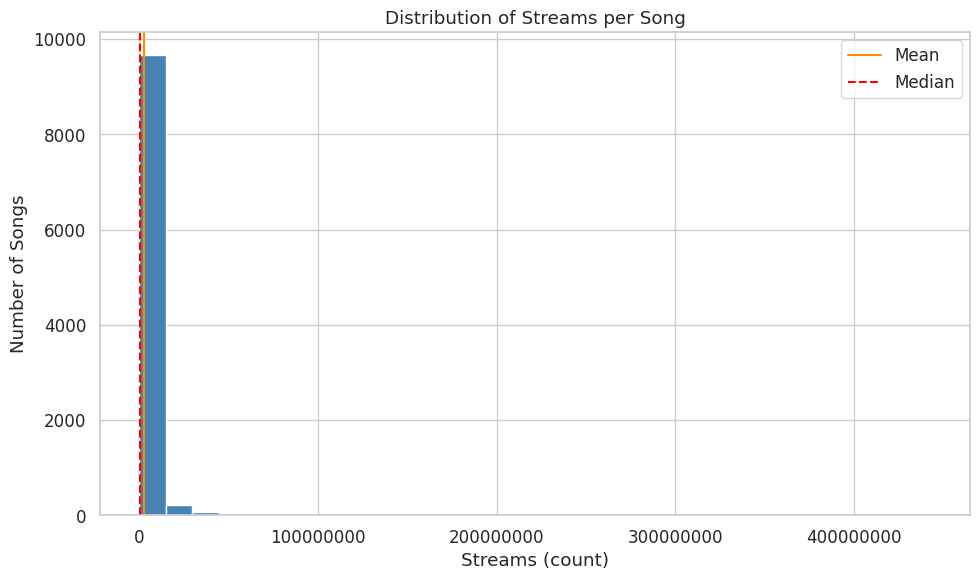

In [13]:
# Calculate the mean and median stream counts.
mean_streams = df["streams"].mean()
median_streams = df["streams"].median()

print(f"Mean streams: {mean_streams:,.0f}")
print(f"Median streams: {median_streams:,.0f}")

# Count songs within 30 stream-count intervals.
plt.figure()
plt.hist(df["streams"], bins=30, color="steelblue", edgecolor="white")

# Mark the mean and median.
plt.axvline(mean_streams, color="darkorange", label="Mean")
plt.axvline(median_streams, color="red", linestyle="--", label="Median")

plt.title("Distribution of Streams per Song")
plt.xlabel("Streams (count)")
plt.ylabel("Number of Songs")
plt.ticklabel_format(style="plain", axis="x")
plt.legend()
plt.tight_layout()
plt.show()

### Key Insights

1. Mean streams are approximately 2.42 million, while median streams are 329,058.
2. The distribution is right-skewed: songs with very high stream counts pull the mean upward.

## Study 2: Stream Distributions by Genre

**Question:** How does the distribution of streams differ across genres?

**Analysis:** Compare the distributions and median stream counts of the ten genres.

**Figure:** A violin plot shows where stream counts are concentrated within each genre.

**Scale:** The horizontal axis uses a logarithmic scale so that both low and high stream counts are visible. Equal distances represent multiplicative changes.

<a name="figure-study-two"></a>

### Figure 2: Stream Distributions by Genre

,median_streams
genre,
Jazz,150482.0
Classical,159661.0
Indie,192274.0
Country,226331.5
Rock,274696.5
R&B,339723.5
Electronic,539456.0
Pop,660266.0
Hip-Hop,779180.5


Songs excluded because streams are not positive: 0


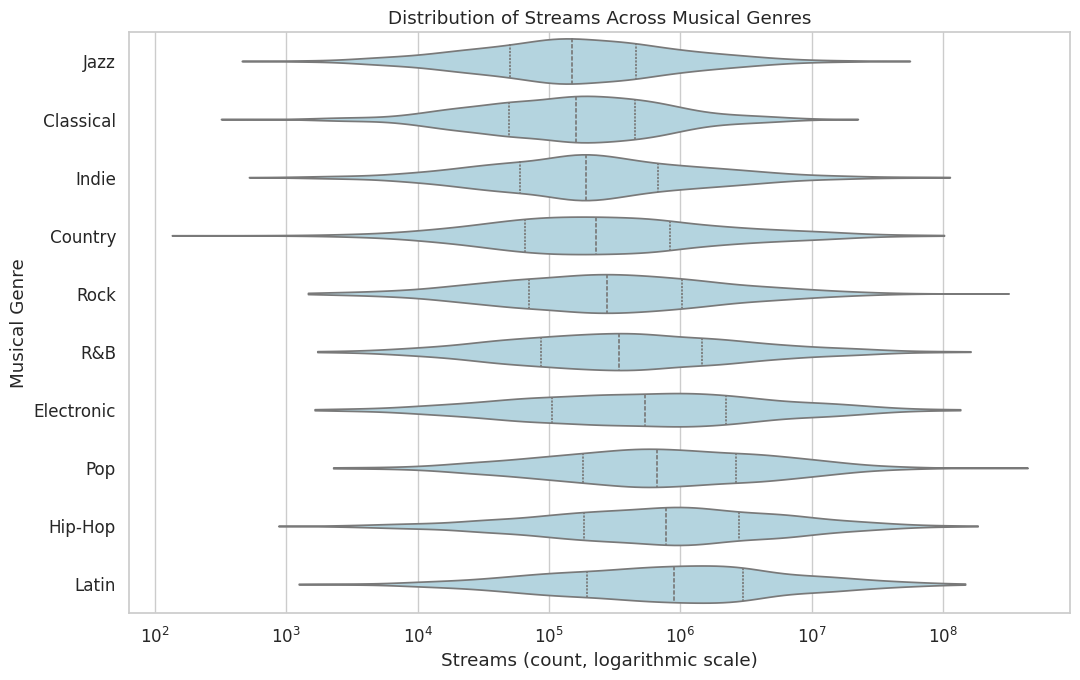

In [14]:
# Calculate and sort median streams by genre.
genre_medians = df.groupby("genre")["streams"].median().sort_values()
display(genre_medians.rename("median_streams").to_frame())

# Logarithmic scales require positive values.
positive_streams = df[df["streams"] > 0]
print("Songs excluded because streams are not positive:",
      len(df) - len(positive_streams))

# Compare the shape of stream distributions across genres.
plt.figure(figsize=(11, 7))
sns.violinplot(
    data=positive_streams,
    x="streams",
    y="genre",
    order=genre_medians.index,
    log_scale=True,
    inner="quart",
    cut=0,
    color="lightblue"
)

plt.title("Distribution of Streams Across Musical Genres")
plt.xlabel("Streams (count, logarithmic scale)")
plt.ylabel("Musical Genre")
plt.tight_layout()
plt.show()

### Key Insights

1. Latin has the highest median streams at 895,084, followed by Hip-Hop at approximately 779,181.
2. Jazz has the lowest median at 150,482. These rankings describe this dataset and do not establish a causal genre effect.

## Study 3: Viral Percentage by Genre

**Question:** How does the percentage of viral songs differ across genres?

**Analysis:** Divide viral songs by all songs within each genre and multiply by 100.

**Figure:** Horizontal bars compare percentages across genres with different sample sizes.

<a name="figure-study-three"></a>

### Figure 3: Viral Percentage by Genre

<a name="figure-study-three"></a>

### Figure 3: Viral Percentage by Genre

,total_songs,viral_songs,viral_percentage
genre,,,
Classical,991,12,1.21
Jazz,965,61,6.32
Indie,993,138,13.90
Country,942,225,23.89
Rock,1084,354,32.66
R&B,950,385,40.53
Electronic,991,502,50.66
Hip-Hop,1052,643,61.12
Pop,1002,619,61.78


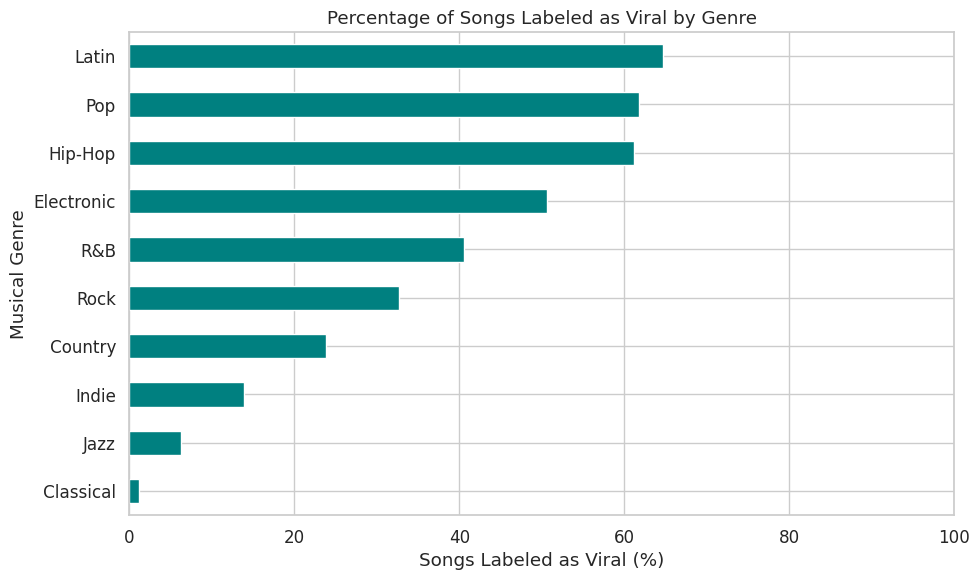

In [15]:
# Count all songs and songs labeled as viral by genre.
genre_summary = df.groupby("genre")["viral"].agg(["count", "sum"])
genre_summary.columns = ["total_songs", "viral_songs"]

# Calculate the viral percentage within each genre.
genre_summary["viral_percentage"] = (
    genre_summary["viral_songs"] / genre_summary["total_songs"] * 100
)

genre_summary = genre_summary.sort_values("viral_percentage")
display(genre_summary.round(2))

# Compare percentages using horizontal bars.
genre_summary["viral_percentage"].plot.barh(color="teal")

plt.title("Percentage of Songs Labeled as Viral by Genre")
plt.xlabel("Songs Labeled as Viral (%)")
plt.ylabel("Musical Genre")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Key Insights

1. Latin has the highest viral percentage (64.66%), followed by Pop (61.78%) and Hip-Hop (61.12%).
2. Classical has the lowest viral percentage at 1.21%.

## Study 4: Danceability and Virality

**Question:** How does danceability differ between viral and non-viral songs?

**Analysis:** Compare the median and spread of danceability in both groups.

**Figure:** A box plot shows each group's median, central 50%, and unusually distant observations.



<a name="figure-study-four"></a>

### Figure 4: Danceability and Virality

,count,median
viral,,
0,6395,0.559
1,3605,0.720


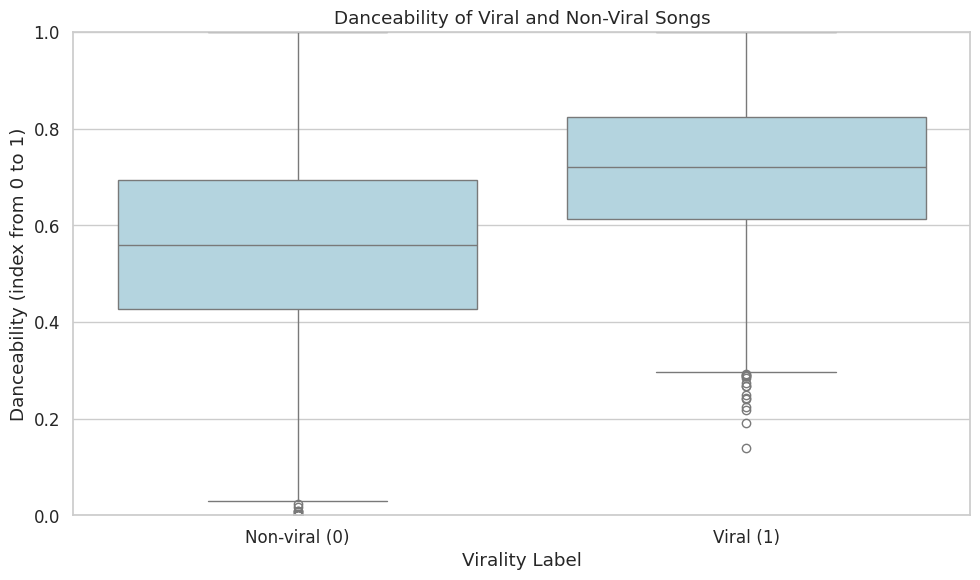

In [16]:
# Display group sizes and median danceability.
dance_summary = df.groupby("viral")["danceability"].agg(["count", "median"])
display(dance_summary)

# Compare the two danceability distributions.
plt.figure()
sns.boxplot(
    data=df,
    x="viral",
    y="danceability",
    order=[0, 1],
    color="lightblue"
)

plt.xticks([0, 1], ["Non-viral (0)", "Viral (1)"])
plt.title("Danceability of Viral and Non-Viral Songs")
plt.xlabel("Virality Label")
plt.ylabel("Danceability (index from 0 to 1)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Key Insights

1. Viral songs have higher median danceability (0.720) than non-viral songs (0.559).
2. The difference is 0.161 index units. This association does not prove that danceability causes virality.

## Study 5: Energy and Streams

**Question:** What relationship exists between energy and streams?

**Analysis:** Calculate Pearson's correlation between energy and streams.

**Figure:** A scatter plot shows individual songs and allows us to examine a possible relationship between two numerical variables.

<a name="figure-study-five"></a>

### Figure 5: Energy and Streams

Pearson correlation: 0.074


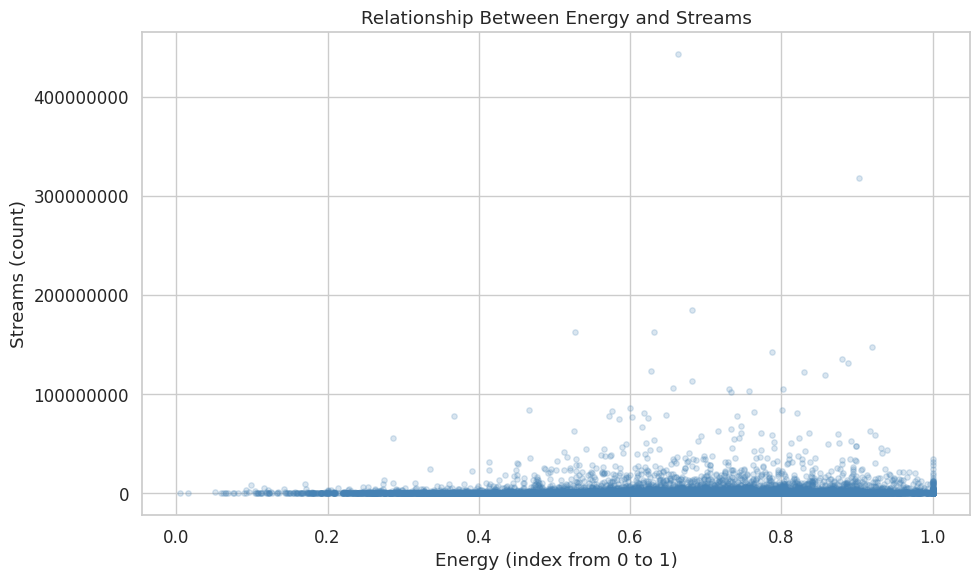

In [17]:
# Calculate the linear correlation.
energy_correlation = df["energy"].corr(df["streams"])
print(f"Pearson correlation: {energy_correlation:.3f}")

# Each point represents one song.
plt.figure()
plt.scatter(
    df["energy"],
    df["streams"],
    alpha=0.2,
    s=15,
    color="steelblue"
)

plt.title("Relationship Between Energy and Streams")
plt.xlabel("Energy (index from 0 to 1)")
plt.ylabel("Streams (count)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### Key Insights

1. Energy and streams have a very weak positive linear correlation (r = 0.074).
2. Energy alone provides little information about streams through a linear relationship in this dataset.

## Study 6: Release Years and Virality

**Question:** How does the percentage of viral songs differ across release years?

**Analysis:** Compare viral percentages across different release years or periods in the dataset.

**Figure:** A line plot shows the percentage of viral songs per release year over time.

<a name="figure-study-six"></a>

### Figure 6: Release Years and Virality

,total_songs,viral_songs,viral_percentage
release_year,,,
2010,600,213,35.50
2011,623,221,35.47
2012,635,222,34.96
2013,652,230,35.28
2014,669,250,37.37
2015,638,239,37.46
2016,582,207,35.57
2017,584,198,33.90
2018,610,218,35.74


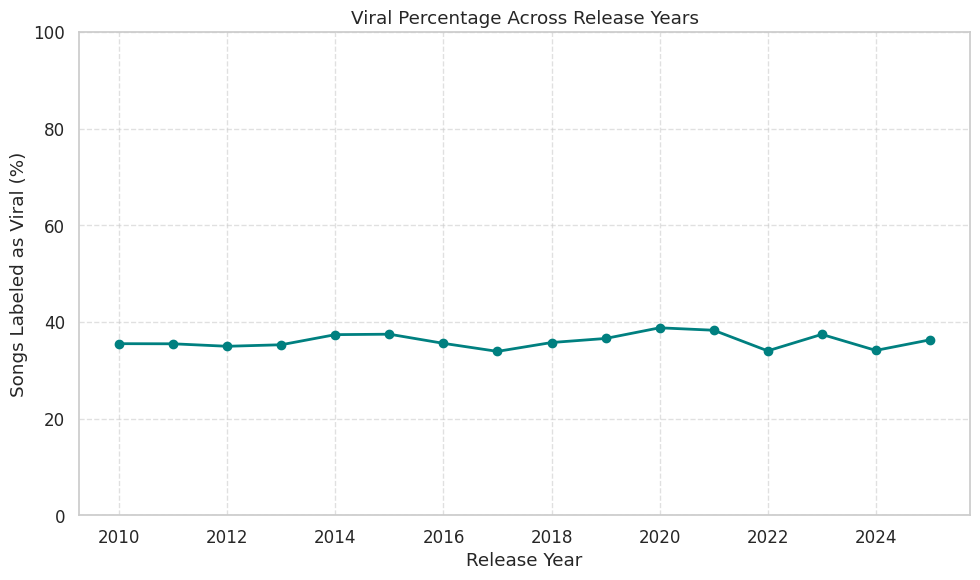

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure dataset is loaded
ruta = '/content/drive/MyDrive/viral_songs.csv'
df = pd.read_csv(ruta)

# Count total songs and viral songs by release year
year_summary = df.groupby("release_year")["viral"].agg(["count", "sum"])
year_summary.columns = ["total_songs", "viral_songs"]

# Calculate percentages of viral songs per year
year_summary["viral_percentage"] = (
    year_summary["viral_songs"] / year_summary["total_songs"] * 100
)

display(year_summary.round(2))

# Plot viral percentage over time (Release Year)
plt.figure(figsize=(10, 6))
plt.plot(
    year_summary.index,
    year_summary["viral_percentage"],
    marker="o",
    linestyle="-",
    color="teal",
    linewidth=2
)

plt.title("Viral Percentage Across Release Years")
plt.xlabel("Release Year")
plt.ylabel("Songs Labeled as Viral (%)")
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Key Insights

1. Analyzing viral percentage over the release years allows us to identify if newer or older songs tend to have higher virality rates.
2. This visualization helps track the evolution of virality criteria or behavior across the different temporal periods present in the dataset.

## Study 7: Relationships Between Musical Characteristics

**Question:** How are danceability, energy, and valence related?

**Analysis:** Calculate Pearson's correlations between the three characteristics.

**Figure:** A heatmap summarizes the strength and direction of several numerical relationships.

These variables will be included together in the regression model.

<a name="figure-study-seven"></a>

### Figure 7: Relationships Between Musical Characteristics

,danceability,energy,valence
danceability,1.000,0.405,0.235
energy,0.405,1.000,0.143
valence,0.235,0.143,1.000


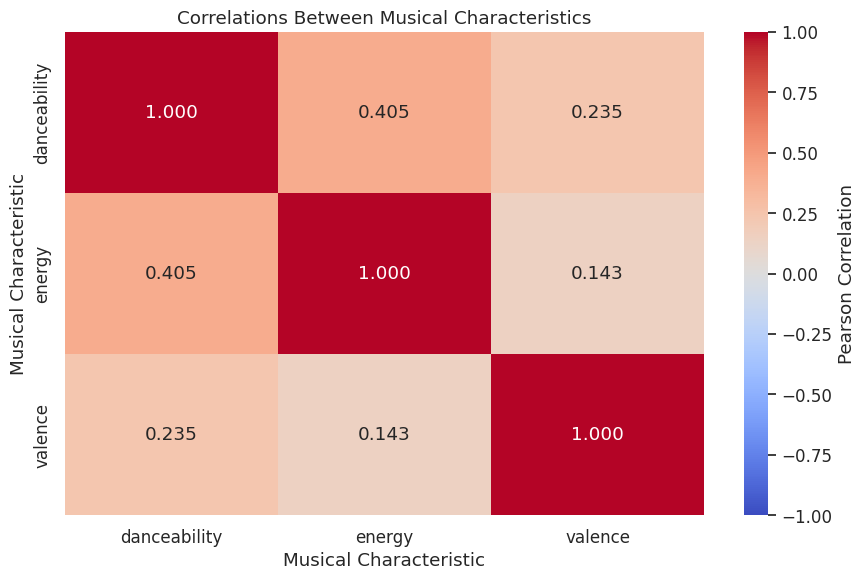

In [19]:
# Select the three characteristics and calculate their correlations.
music_features = df[["danceability", "energy", "valence"]]
correlation_matrix = music_features.corr()

display(correlation_matrix.round(3))

# Use colors and numbers to show the correlations.
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlations Between Musical Characteristics")
plt.xlabel("Musical Characteristic")
plt.ylabel("Musical Characteristic")
plt.tight_layout()
plt.show()

### Key Insights

1. Danceability and energy have the strongest correlation among the three pairs (r = 0.405).
2. Valence has weaker positive correlations with danceability (r = 0.235) and energy (r = 0.143).

## Study 8: Explaining Streams with Multiple Linear Regression

**Question:** How are danceability, energy, and valence jointly associated with streams?

**Dependent variable (Y):** streams.

**Explanatory variables (X):** danceability, energy, and valence.

**Model:**

Estimated streams = intercept + b_danceability × danceability + b_energy × energy + b_valence × valence

**Figure:** A hexagonal density plot compares observed and estimated streams. Each hexagon groups songs with similar observed and estimated values. Color indicates the number of songs.

This grouping reduces the overlap that occurs when displaying 10,000 individual points.

<a name="figure-study-eight"></a>

### Figure 8: Observed vs. Estimated Streams

,Variable,Coefficient
0,danceability,5253672.70
1,energy,1467948.95
2,valence,1324229.29


Intercept: -2,526,118.67
R-squared: 0.0160
Variation explained: 1.60%


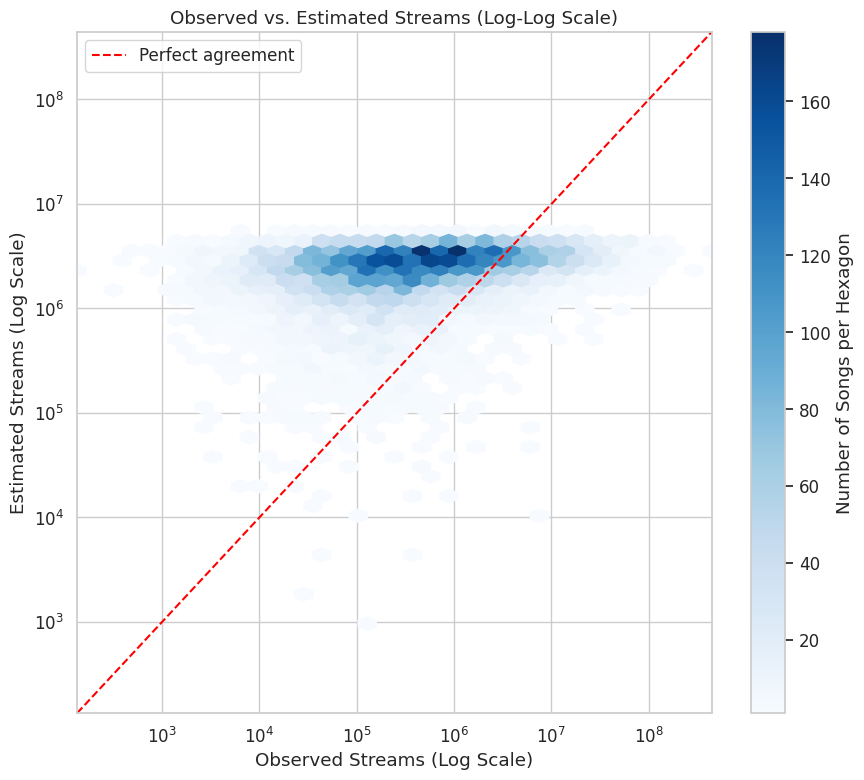

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd

# Select the explanatory variables and outcome.
X = df[["danceability", "energy", "valence"]]
y = df["streams"]

# Fit the regression using all songs.
model = LinearRegression()
model.fit(X, y)

# Display the estimated coefficients.
coefficients = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_
})

display(coefficients.round(2))
print(f"Intercept: {model.intercept_:,.2f}")

# Calculate R-squared within the same dataset.
r_squared = model.score(X, y)
print(f"R-squared: {r_squared:.4f}")
print(f"Variation explained: {r_squared * 100:.2f}%")

# Calculate estimated streams.
predicted_streams = model.predict(X)

# Plotting using a logarithmic scale to correct the scale issue
plt.figure(figsize=(9, 8))

# Filter out non-positive values if any (though in this dataset they are positive)
valid_mask = (y > 0) & (predicted_streams > 0)
y_valid = y[valid_mask]
pred_valid = predicted_streams[valid_mask]

# Hexagonal binning with logarithmic scale for axes
plt.hexbin(
    y_valid,
    pred_valid,
    gridsize=35,
    mincnt=1,
    cmap="Blues",
    xscale='log',
    yscale='log'
)

plt.colorbar(label="Number of Songs per Hexagon")

# Add a line showing perfect agreement on log scale
min_val = min(y_valid.min(), pred_valid.min())
max_val = max(y_valid.max(), pred_valid.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect agreement"
)

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Observed vs. Estimated Streams (Log-Log Scale)")
plt.xlabel("Observed Streams (Log Scale)")
plt.ylabel("Estimated Streams (Log Scale)")
plt.legend()
plt.tight_layout()
plt.show()

### Estimated Equation

Estimated streams = −2,526,118.67 + 5,253,672.70 × danceability + 1,467,948.95 × energy + 1,324,229.29 × valence

### Key Insights

1. All three coefficients are positive. Holding energy and valence constant, a 0.1-unit increase in danceability is associated with approximately 525,367 additional estimated streams.
2. R² = 0.016: the model explains only 1.60% of stream variation within this dataset, indicating limited explanatory power.

### Interpretation and Limitations

R² is the proportion of variation explained, not the percentage of correct predictions.

The model was fitted and evaluated on the same songs. Performance on new songs has not been tested, and the coefficients do not establish causation.

Linear regression can produce negative stream estimates, which are unrealistic counts and limit its use for prediction.

## Final Conclusions

1. Streams are unevenly distributed. The mean greatly exceeds the median because some songs have extremely high stream counts.

2. Latin leads in both median streams and viral percentage. However, the rankings differ: Hip-Hop ranks second in median streams, while Pop ranks second in viral percentage.

3. Viral songs have higher median danceability, and the high-tempo group has the highest viral percentage. These are descriptive associations.

4. Energy has a very weak linear relationship with streams. Together, danceability, energy, and valence explain only 1.60% of stream variation.

### Practical Implication

These musical characteristics alone provide limited information about stream counts. Additional information about promotion, audience, playlist exposure, and platform should be collected before making decisions.

### Limitations

- The original source and sampling method are not documented.
- The generic song and artist names suggest that the dataset may be synthetic, but this is unconfirmed.
- The platform, stream measurement period, and viral labeling criteria are unknown.
- Group differences were not tested for statistical significance.
- The regression was evaluated using the same songs used to fit it.
- Findings describe this dataset and do not establish causation.